<a href="https://colab.research.google.com/github/sahanashree20/Retail-Store-Inventory-Forecasting/blob/main/Customer_Purchase_Behavior_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install pandas numpy matplotlib seaborn scipy statsmodels scikit-learn

In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

sns.set_theme(style="whitegrid")

In [4]:
from google.colab import files
uploaded = files.upload()

In [5]:
import pandas as pd

df = pd.read_csv("/content/customer_purchase_behavior_dataset.csv")

display(df.head())
print(df.shape)

,Transaction_ID,Customer_ID,Purchase_Date,Age,Gender,Category,Purchase_Amount_USD,Review_Rating,Discount_Applied,Previous_Purchases,Frequency_of_Purchases,Purchase_Channel,Loyalty_Status
0,TXN000001,10103,2025-09-10,32,Female,Clothing,71.24,4.7,No,5,Monthly,Online,Member
1,TXN000002,10180,2025-02-24,46,Male,Electronics,134.92,4.7,Yes,3,Monthly,In-Store,Non-Member
2,TXN000003,10093,2025-06-04,25,Male,Beauty,40.31,4.2,No,2,Quarterly,In-Store,Member
3,TXN000004,10015,2025-04-01,22,Male,Electronics,193.57,3.3,Yes,7,Rarely,Online,Member
4,TXN000005,10107,2025-12-05,46,Male,Electronics,206.83,3.7,No,3,Quarterly,In-Store,Member


(1200, 13)


Clean the data

In [7]:
# Remove duplicate rows
df = df.drop_duplicates().copy()

# Standardize column names
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)

print(df.columns.tolist())


['transaction_id', 'customer_id', 'purchase_date', 'age', 'gender', 'category', 'purchase_amount_usd', 'review_rating', 'discount_applied', 'previous_purchases', 'frequency_of_purchases', 'purchase_channel', 'loyalty_status']


In [8]:
df["purchase_amount_usd"] = pd.to_numeric(
    df["purchase_amount_usd"], errors="coerce"
)

df = df.dropna(subset=["purchase_amount_usd"])

df = df[df["purchase_amount_usd"] >= 0]

print("Cleaned dataset shape:", df.shape)

Cleaned dataset shape: (1200, 13)


In [9]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
transaction_id,1200,1200,TXN001184,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_id,1200.0,NaN,NaN,NaN,10101.25,57.6245,10001.0,10051.0,10103.0,10150.25,10200.0
purchase_date,1200,354,2025-05-30,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,1200.0,NaN,NaN,NaN,44.335,15.145041,18.0,31.0,45.0,57.0,70.0
gender,1200,3,Female,587,NaN,NaN,NaN,NaN,NaN,NaN,NaN
category,1200,6,Clothing,288,NaN,NaN,NaN,NaN,NaN,NaN,NaN
purchase_amount_usd,1200.0,NaN,NaN,NaN,111.0973,65.098115,5.0,70.2725,95.98,138.6175,647.74
review_rating,1200.0,NaN,NaN,NaN,3.962333,0.668496,1.8,3.5,4.0,4.5,5.0
discount_applied,1200,2,No,740,NaN,NaN,NaN,NaN,NaN,NaN,NaN
previous_purchases,1200.0,NaN,NaN,NaN,5.0475,2.279526,0.0,3.0,5.0,6.0,16.0


4. Perform the five main analyses
Analysis 1 — Customer spending patterns

In [10]:
total_sales = df["purchase_amount_usd"].sum()
average_purchase = df["purchase_amount_usd"].mean()
median_purchase = df["purchase_amount_usd"].median()

print(f"Total sales: ${total_sales:,.2f}")
print(f"Average purchase: ${average_purchase:,.2f}")
print(f"Median purchase: ${median_purchase:,.2f}")

Total sales: $133,316.76
Average purchase: $111.10
Median purchase: $95.98


Plot purchase amounts:

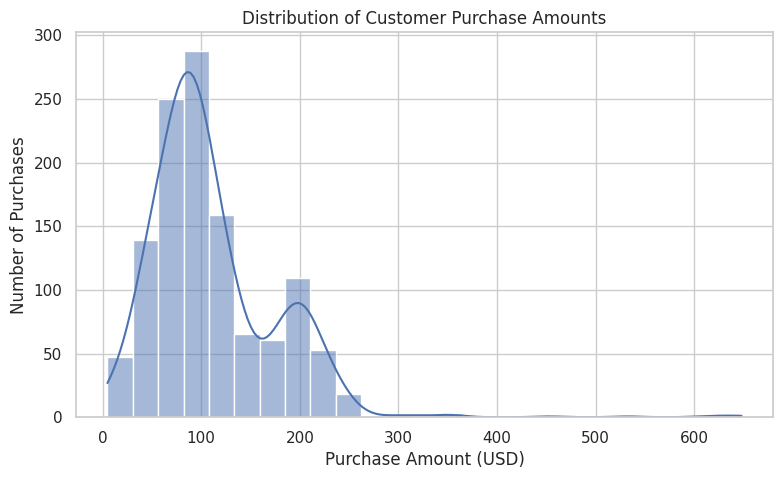

In [11]:
plt.figure(figsize=(9, 5))

sns.histplot(
    df["purchase_amount_usd"],
    bins=25,
    kde=True
)

plt.title("Distribution of Customer Purchase Amounts")
plt.xlabel("Purchase Amount (USD)")
plt.ylabel("Number of Purchases")

plt.show()

Compare product categories:

,sum,mean,count
category,,,
Electronics,50161.35,206.425309,243
Home & Kitchen,27246.75,119.503289,228
Clothing,25345.86,88.006458,288
Sports,13388.23,97.724307,137
Beauty,12398.10,63.255612,196
Books,4776.47,44.226574,108


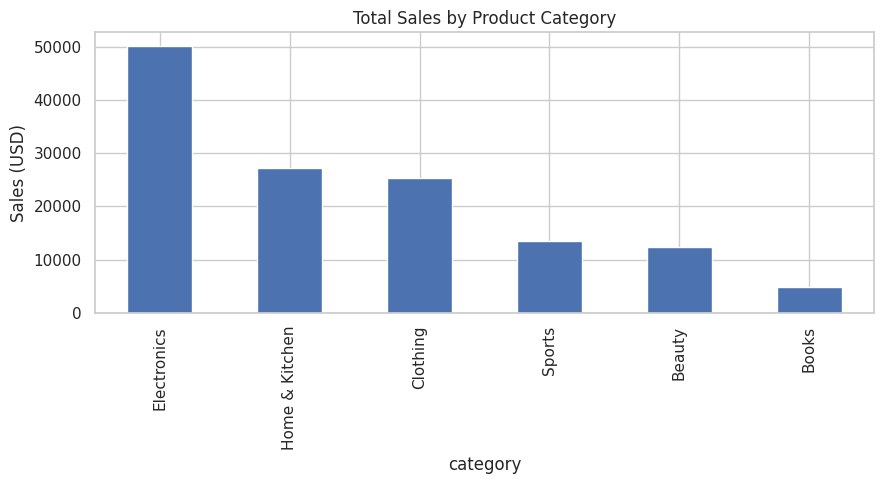

In [12]:
category_sales = (
    df.groupby("category")["purchase_amount_usd"]
    .agg(["sum", "mean", "count"])
    .sort_values("sum", ascending=False)
)

display(category_sales)

category_sales["sum"].plot(
    kind="bar",
    figsize=(9, 5),
    title="Total Sales by Product Category"
)

plt.ylabel("Sales (USD)")
plt.tight_layout()
plt.show()

Analysis 2 — Hypothesis testing
Test whether average purchase amounts differ between customers who received a discount and those who did not.

Hypotheses:
- \(H_0\): The two groups have the same average purchase amount.
- \(H_1\): The two groups have different average purchase amounts.

In [13]:
print(df["discount_applied"].value_counts(dropna=False))

discount_applied
No     740
Yes    460
Name: count, dtype: int64


In [14]:
discounted = df.loc[
    df["discount_applied"].astype(str).str.strip().str.lower().eq("yes"),
    "purchase_amount_usd"
].dropna()

not_discounted = df.loc[
    df["discount_applied"].astype(str).str.strip().str.lower().eq("no"),
    "purchase_amount_usd"
].dropna()

print("Discounted average:", discounted.mean())
print("Non-discounted average:", not_discounted.mean())

t_stat, p_value = stats.ttest_ind(
    discounted,
    not_discounted,
    equal_var=False
)

print("T-statistic:", t_stat)
print("P-value:", p_value)

if p_value < 0.05:
    print("Reject H0: evidence of a difference in group means.")
else:
    print("Fail to reject H0: insufficient evidence of a difference.")

Discounted average: 103.01752173913043
Non-discounted average: 116.11986486486487
T-statistic: -3.4691152387950304
P-value: 0.0005437403585556699
Reject H0: evidence of a difference in group means.


Analysis 3 — Correlation analysis

In [15]:
numeric_columns = [
    "age",
    "previous_purchases",
    "review_rating",
    "purchase_amount_usd"
]

numeric_df = df[
    [c for c in numeric_columns if c in df.columns]
].apply(pd.to_numeric, errors="coerce")

correlation_matrix = numeric_df.corr(method="pearson")

display(correlation_matrix)

,age,previous_purchases,review_rating,purchase_amount_usd
age,1.000000,-0.026915,-0.019907,0.105128
previous_purchases,-0.026915,1.000000,0.002160,0.054983
review_rating,-0.019907,0.002160,1.000000,0.000649
purchase_amount_usd,0.105128,0.054983,0.000649,1.000000


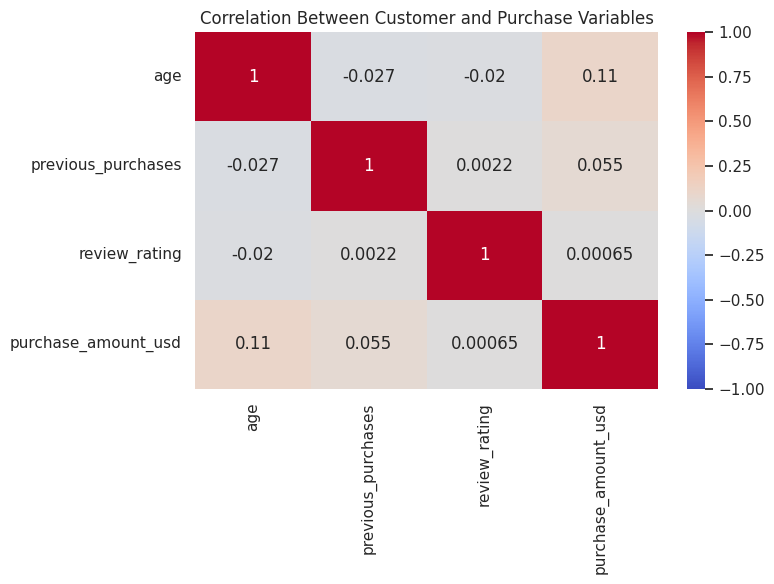

In [16]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Customer and Purchase Variables")
plt.tight_layout()
plt.show()

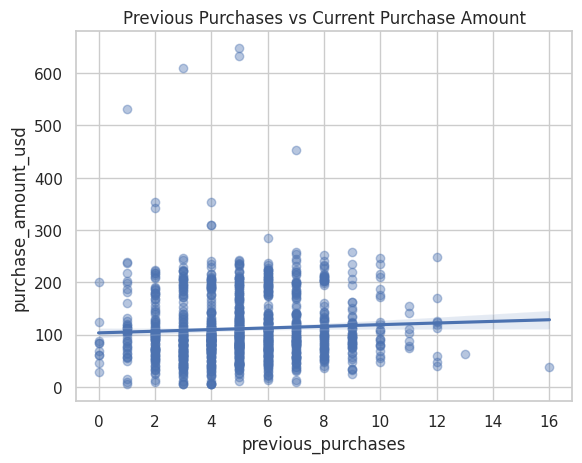

In [17]:
sns.regplot(
    data=df,
    x="previous_purchases",
    y="purchase_amount_usd",
    scatter_kws={"alpha": 0.4}
)

plt.title("Previous Purchases vs Current Purchase Amount")
plt.show()

Analysis 4 — Outlier detection using the IQR method

In [18]:
purchase = df["purchase_amount_usd"]

Q1 = purchase.quantile(0.25)
Q3 = purchase.quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (purchase < lower_bound) |
    (purchase > upper_bound)
]

print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Number of outliers:", len(outliers))

display(outliers.head(10))

Lower bound: -32.24499999999999
Upper bound: 241.135
Number of outliers: 21


,transaction_id,customer_id,purchase_date,age,gender,category,purchase_amount_usd,review_rating,discount_applied,previous_purchases,frequency_of_purchases,purchase_channel,loyalty_status
15,TXN000016,10152,2025-12-28,53,Male,Electronics,252.78,4.6,No,8,Monthly,In-Store,Non-Member
28,TXN000029,10058,2025-09-24,64,Female,Electronics,245.75,4.6,No,10,Quarterly,Online,Member
81,TXN000082,10044,2025-11-02,69,Female,Electronics,245.26,4.2,No,7,Rarely,Online,Member
185,TXN000186,10121,2025-12-03,54,Female,Electronics,243.24,2.2,No,5,Quarterly,Online,Member
210,TXN000211,10131,2025-10-02,27,Female,Electronics,647.74,3.7,No,5,Monthly,In-Store,Non-Member
349,TXN000350,10097,2025-01-26,26,Female,Home & Kitchen,309.97,5.0,Yes,4,Weekly,Online,Member
389,TXN000390,10174,2025-09-03,33,Female,Home & Kitchen,353.34,3.2,No,4,Quarterly,Online,Non-Member
528,TXN000529,10069,2025-11-10,46,Female,Electronics,253.65,4.6,No,7,Quarterly,Online,Member
529,TXN000530,10100,2025-09-23,70,Male,Electronics,532.13,3.6,No,1,Quarterly,In-Store,Non-Member
545,TXN000546,10084,2025-02-10,66,Female,Electronics,610.20,4.8,No,3,Weekly,In-Store,Member


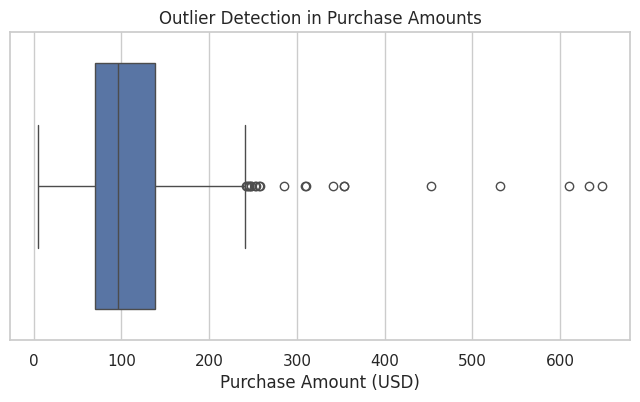

In [19]:
plt.figure(figsize=(8, 4))

sns.boxplot(x=df["purchase_amount_usd"])

plt.title("Outlier Detection in Purchase Amounts")
plt.xlabel("Purchase Amount (USD)")

plt.show()

In [20]:
features = [
    "age",
    "previous_purchases",
    "review_rating"
]

target = "purchase_amount_usd"

model_df = df[features + [target]].copy()

for col in model_df.columns:
    model_df[col] = pd.to_numeric(
        model_df[col], errors="coerce"
    )

model_df = model_df.dropna()

X = model_df[features]
y = model_df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [21]:
model = LinearRegression()

model.fit(X_train, y_train)

predictions = model.predict(X_test)

mae = mean_absolute_error(y_test, predictions)
r2 = r2_score(y_test, predictions)

print("Mean Absolute Error:", round(mae, 2))
print("R-squared:", round(r2, 3))

Mean Absolute Error: 46.71
R-squared: 0.007


,Actual,Predicted
1178,69.93,101.305733
865,26.37,99.087685
101,121.72,116.892122
439,58.54,119.214443
58,92.93,115.043462
1120,92.08,105.757537
323,86.81,111.351370
974,47.73,103.256343
411,95.40,99.905127
855,168.14,117.530691


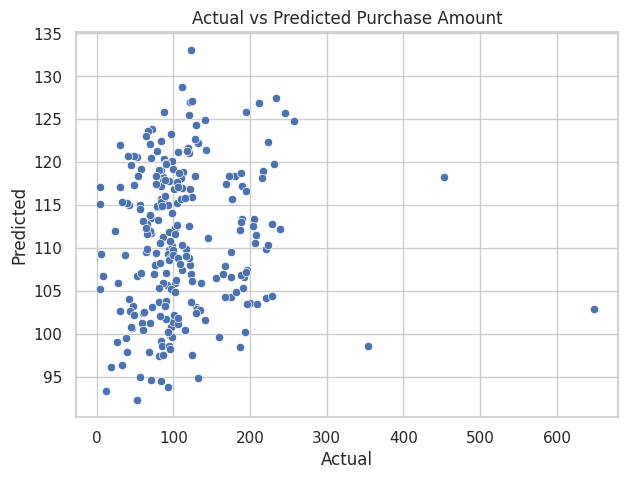

In [22]:
results = pd.DataFrame({
    "Actual": y_test,
    "Predicted": predictions
})

display(results.head(10))

plt.figure(figsize=(7, 5))

sns.scatterplot(
    data=results,
    x="Actual",
    y="Predicted"
)

plt.title("Actual vs Predicted Purchase Amount")
plt.show()